In [1]:
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/osmi/mental-health-in-tech-survey/survey.csv


# Introduction

More and more people suffer from burnout at work.
Using the Mental Health in Tech Survey, I will explore whether people in tech industry are more likely to have mental health issue.
Besides, whether the possibility of mental illness differ by country or gender.
In addition, what factors have huge influence on mental health at work.

In [2]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/kaggle/input/datasets/osmi/mental-health-in-tech-survey/survey.csv', parse_dates = True)
df.head()

,Timestamp,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,remote_work,...,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
count,1259,1259,1259,744,1241,1259,1259,995,1259,1259,...,1259,1259,1259,1259,1259,1259,1259,1259,1259,164
unique,1246,49,48,45,2,2,2,4,6,2,...,5,3,3,3,3,3,3,3,2,160
top,2014-08-27 12:31:41,Male,United States,CA,No,No,Yes,Sometimes,6-25,No,...,Don't know,No,No,Some of them,Yes,No,Maybe,Don't know,No,* Small family business - YMMV.
freq,2,615,751,138,1095,767,637,465,290,883,...,563,490,925,774,516,1008,557,576,1075,5


In [8]:
df.describe(include='object')

,Timestamp,Gender,Country,state,self_employed,family_history,treatment,work_interfere,no_employees,remote_work,...,leave,mental_health_consequence,phys_health_consequence,coworkers,supervisor,mental_health_interview,phys_health_interview,mental_vs_physical,obs_consequence,comments
count,1259,1259,1259,744,1241,1259,1259,995,1259,1259,...,1259,1259,1259,1259,1259,1259,1259,1259,1259,164
unique,1246,3,48,45,2,2,2,4,6,2,...,5,3,3,3,3,3,3,3,2,160
top,2014-08-27 12:31:41,male,United States,CA,No,No,Yes,Sometimes,6-25,No,...,Don't know,No,No,Some of them,Yes,No,Maybe,Don't know,No,* Small family business - YMMV.
freq,2,990,751,138,1095,767,637,465,290,883,...,563,490,925,774,516,1008,557,576,1075,5


# Question1
Do people in Tech company get more chances of mental illness?

Text(0.5, 1.0, 'Number of People by Recieving Treatment or not')

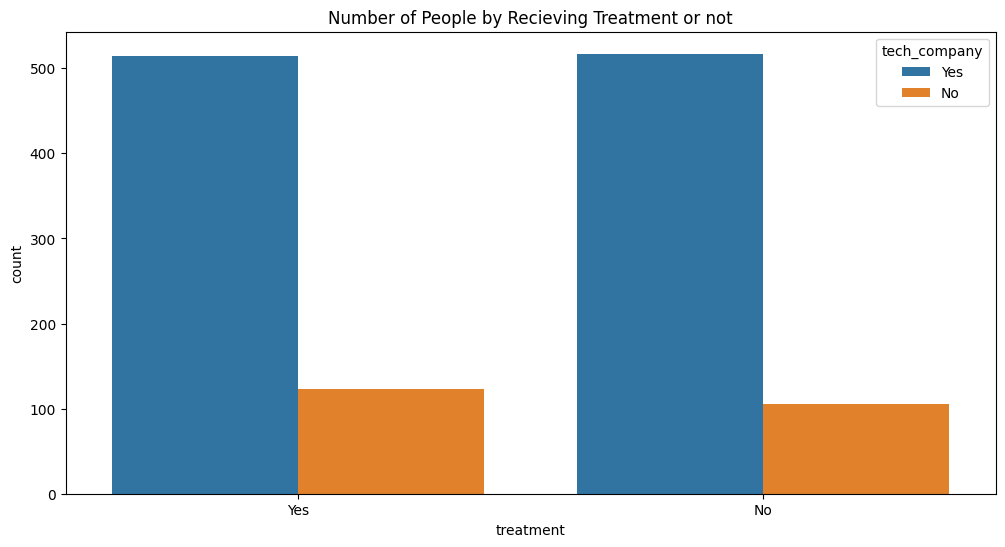

In [15]:
df.groupby(['treatment','tech_company']).size()
plt.figure(figsize=(12,6))
sns.countplot(data=df, x = 'treatment', hue='tech_company')
plt.title('Number of People by Receiving Treatment or not')

## Result
It seems the possibility of receiving treatment doesn't have much difference responding to whether working in Tech Company or not. 

However, because the willingness to receiving treatment may differ by industries, so it is hard to presume whether people in Tech company get more chances of mental illness.

# Question2
Does the possibility of mental illness differ by country?

In [4]:
df['Country'].value_counts()

Country
United States             751
United Kingdom            185
Canada                     72
Germany                    45
Netherlands                27
Ireland                    27
Australia                  21
France                     13
India                      10
New Zealand                 8
Poland                      7
Italy                       7
Sweden                      7
Switzerland                 7
South Africa                6
Brazil                      6
Belgium                     6
Israel                      5
Singapore                   4
Bulgaria                    4
Russia                      3
Austria                     3
Finland                     3
Mexico                      3
Denmark                     2
Greece                      2
Portugal                    2
Colombia                    2
Croatia                     2
Slovenia                    1
Costa Rica                  1
Latvia                      1
Uruguay                     1
Sp

Text(0.5, 1.0, 'Percentage of People Reciving Treatment by Country')

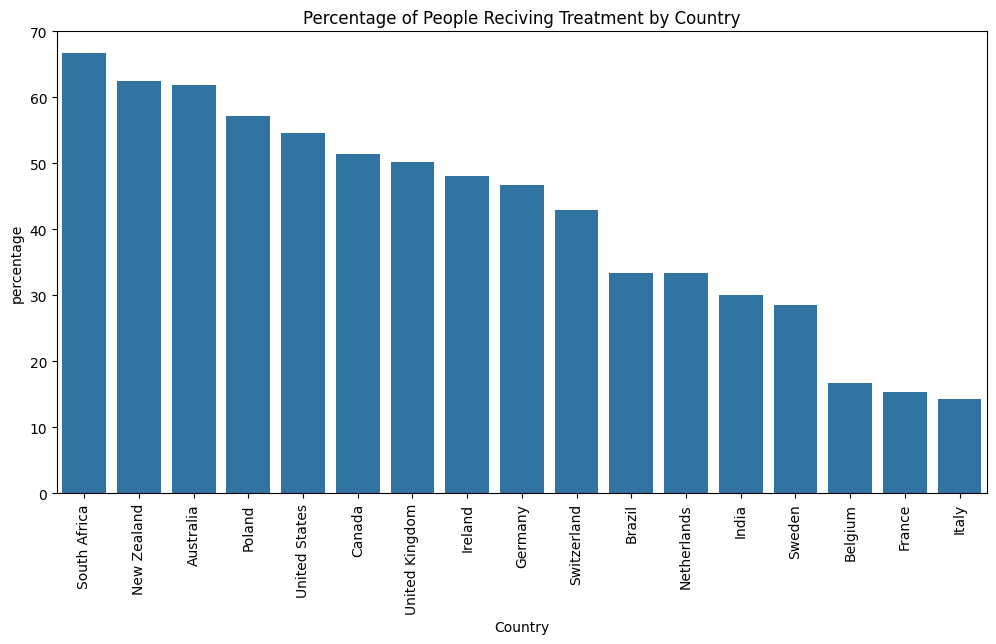

In [14]:
df_filtered = df.groupby('Country').filter(lambda group: len(group) >5)
df_by_country = (
    df_filtered.assign(percentage = df_filtered['treatment'].eq('Yes'))
    .groupby('Country')['percentage']
    .mean().mul(100).round(2)
    .sort_values(ascending=False).reset_index()
)
plt.figure(figsize=(12,6))
plt.xticks(rotation = 90)
sns.barplot(data = df_by_country, x = 'Country', y = 'percentage')
plt.title('Percentage of People Receiving Treatment by Country')

## Result
There is a difference in percentage of mental illness treatment by countries. 

People in South Africa have the highest possibility of receiving treatment, while Italy have the lowest chances.

However, we cannot tell whether people are more likely to have mental health issues in those top ranking countries, because the result may due to whether people choose to receive treatment or not when they have mental health issues.

# Question3
Does the possibility of receiving treatment differ by genders?

In [23]:
df['Gender'].value_counts()

Gender
male             990
female           247
other/unknown     22
Name: count, dtype: int64

In [24]:
male_values = ['M',
    'Male',
    'male',
    'm',
    'maile',
    'Cis Male',
    'Mal',
    'Male (CIS)',
    'Make',
    'Male ',
    'Man',
    'msle',
    'Mail',
    'cis male',
    'Malr',
    'Cis Man',
]
female_values = [
    'Female',
    'female',
    'Cis Female',
    'F',
    'Woman',
    'f',
    'Femake',
    'woman',
    'Female ',
    'femail',
    'Female (cis)',
    'cis-female/femme',
]

replace_map = {
    **{word:'male' for word in male_values},
    **{word:'female' for word in female_values}
}

df["Gender_adjusted"] = df['Gender'].replace(replace_map).where(lambda s: s.isin(['male','female']),'other')

df['Gender_adjusted'].value_counts()

Gender_adjusted
male      990
female    247
other      22
Name: count, dtype: int64

Text(0.5, 1.0, 'Percentage of People Receiving Treatment by Gender')

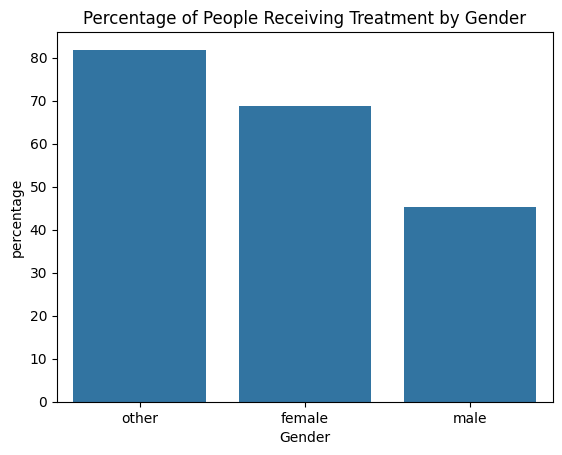

In [25]:
df_by_gender =(
    df.assign(percentage = df['treatment'].eq('Yes'))
    .groupby('Gender_adjusted')['percentage']
    .mean().mul(100).round(2)
    .sort_values(ascending = False)
    .reset_index()
)
sns.barplot(data = df_by_gender, x = 'Gender_adjusted', y = 'percentage')
plt.xlabel('Gender')
plt.title('Percentage of People Receiving Treatment by Gender')

## Result
There is a possiblity that sexual minority tends to be more likely to receive treatment for mental health issues.

However, there is a possibility that sexual minority are more likely to persue for help.